## Day: Bug O:SPY250127C00620000  Found non-finite values in spot after conversion...?

In [1]:

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.massive.client
%aimport quantdata.massive.processing
%aimport quantdata.massive.options.contracts
%aimport quantdata.ncde.implied.day

In [2]:



from datetime import date
from cdxcore.jcpool import JCPool
from cdxcore.pretty import PrettyObject
from cdxcore.subdir import SubDir
from cdxcore.util import fmt_list
from cdxcore.uniquehash import named_unique_filename48_8
import polars as pl

from quantdata.biz_calendar import prev_business_day
from quantdata.massive.client import MassiveClient
from quantdata.pool import PoolConfig
from quantdata.massive.options.contracts import ContractsFilter, filter_contracts, REJECTED
from quantdata.massive.processing import TradeQuoteAlignmentConfig, align_trades_to_quotes, align_quotes_to_trades, filter_valid_quotes, filter_valid_trades

from cdxcore.version import version
from cdxcore.verbose import Context
from dataclasses import asdict, dataclass, field
from cdxcore.uniquehash import unique_hash8 
import numpy as np
import math
import warnings

from IPython.display import display, Markdown, clear_output

from quantdata.ncde.implied.day import OptionQuotesDayConfig, generate_day

option_quotes_day_config = OptionQuotesDayConfig()
ticker     = "SPY"
d          = prev_business_day(date(2025, 1, 24), exclude_half_days=True, count_start=True )
pool_config= PoolConfig(num_workers=4, threading=False) 
results    = generate_day( ticker, d, option_quotes_day_config=option_quotes_day_config, pool_config=pool_config, verbose=Context.all )

for expiry, df_dict in results.items():
    opt_tickers = sorted( df_dict["opt_ticker"].unique().to_list() )
    df_opt = df_dict.filter(pl.col("opt_ticker") == opt_tickers[0])
    display(df_opt)



00: SPY 2025-01-24: Starting data generation with config mxn=1000,max_dte=7,max_mns=2,min_opt_vol_k=0,bck=250,fwd=250):
00: SPY 2025-01-24: Limiting to at most 1000 options per expiry, selected by smallest absolute nms5:
01:   SPY 2025-01-24 expiry 2025-01-24: Selected 38/38 options, sorted by smallest absolute nms5. Resulting options range from nms5 -0.821 to 0.867.
01:   SPY 2025-01-24 expiry 2025-01-27: Selected 40/40 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.025 to 1.060.
01:   SPY 2025-01-24 expiry 2025-01-28: Selected 46/46 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.257 to 1.183.
01:   SPY 2025-01-24 expiry 2025-01-29: Selected 51/51 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.279 to 1.295.
01:   SPY 2025-01-24 expiry 2025-01-30: Selected 61/61 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.392 to 1.399.
01:   SPY 2025-01-24 expiry 2025-0

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,nms5,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,1.000082,100.0,0.000004,null,0.000003,0.000002,0.012095,0.000402,1.000074,0.000008,2.0,0.5,3200.0,0.84375,null,1.0,null,null,null,null,0.799997,null,null,null,null,2025-01-24,2025-01-24,0.98811,"""SPY""","""O:SPY250124C00602500""",true,true,609.75,0.000016,447.056232,0.011964,true,1.0,5.9006e-97,1.8732e-101,2.9503e-101,0.01,0.888968,19.127918,0.010666,0.295058,0.175645,0.954944,13.333376,0.005346,0.106344,0.1263
null,null,1.000082,100.0,0.000008,null,0.000008,0.000007,0.012079,0.000385,1.000074,0.000008,2.0,0.5,2900.0,0.931034,null,1.0,-0.001356,null,0.0,0.0,0.799993,0.000004,null,0.000004,0.000005,2025-01-24,2025-01-24,0.98811,"""SPY""","""O:SPY250124C00602500""",true,true,609.75,0.000016,447.05637,0.011964,true,1.0,5.8946e-97,1.8713e-101,2.9473e-101,0.01,0.893055,18.955525,0.010382,0.282116,0.172529,0.958909,12.695002,0.004963,0.096244,0.123136
null,null,1.000082,10.0,0.000018,null,0.000011,0.000011,0.011964,0.000139,1.000074,0.000008,20.0,0.5,3800.0,0.710526,null,1.0,-0.009504,null,0.0,0.0,0.799985,0.00001,null,0.000004,0.000003,2025-01-24,2025-01-24,0.98811,"""SPY""","""O:SPY250124C00602500""",true,true,609.75,0.000016,447.056685,0.011964,true,1.0,5.8809e-97,1.8669e-101,2.9405e-101,0.01,0.953028,13.624773,0.005528,0.111273,0.127804,1.0,5.8809e-97,1.8669e-101,2.9405e-101,0.01
null,null,1.000016,50.0,0.000032,null,0.000032,0.000032,0.011997,0.0005,1.000025,0.000008,4.0,0.5,600.0,0.166667,null,-1.0,0.002742,null,-0.000066,-0.000049,0.799974,0.000014,null,0.000021,0.000021,2025-01-24,2025-01-24,0.98811,"""SPY""","""O:SPY250124C00602500""",true,true,609.75,0.000016,447.060551,0.011915,true,1.0,3.7711e-96,1.1971e-100,1.8855e-100,0.01,0.882888,19.431173,0.011078,0.313385,0.179599,0.967495,11.173297,0.004097,0.07452,0.115494
null,null,1.000016,50.0,0.000032,null,0.000032,0.000032,0.011997,0.0005,1.000025,0.000008,178.0,0.5,600.0,0.166667,null,-1.0,0.0,null,0.0,0.0,0.799974,8.5897e-9,null,0.0,0.0,2025-01-24,2025-01-24,0.98811,"""SPY""","""O:SPY250124C00602500""",true,true,609.75,0.000016,447.060552,0.011915,true,1.0,3.7711e-96,1.1971e-100,1.8855e-100,0.01,0.882888,19.431173,0.011078,0.313385,0.179599,0.967495,11.173297,0.004097,0.07452,0.115494
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,0.997015,100.0,0.999979,null,0.999979,0.999979,0.008651,0.000763,0.997007,0.000008,153.0,0.51634,400.0,0.5,null,1.0,-0.003777,null,-0.000049,-0.000058,0.000017,0.000011,null,0.000012,0.000012,2025-01-24,2025-01-24,0.98811,"""SPY""","""O:SPY250124C00602500""",true,true,609.75,0.000016,481.724405,0.008897,true,1.0,0.0,0.0,0.0,0.01,1.0,7.9833e-9,2.6311e-15,9.9791e-8,5.0,1.0,0.0,0.0,0.0,0.01
null,null,0.997048,100.0,0.999981,null,0.999981,0.999981,0.008651,0.000763,0.99704,0.000025,153.0,0.51634,1500.0,0.733333,null,0.333333,0.0,null,0.000033,0.000033,0.000015,0.000002,null,0.000002,0.000002,2025-01-24,2025-01-24,0.98811,"""SPY""","""O:SPY250124C00602500""",true,true,609.75,0.000016,481.721997,0.00893,true,1.0,0.0,0.0,0.0,0.01,1.0,7.4981e-10,2.2655e-16,9.3727e-9,5.0,1.0,0.0,0.0,0.0,0.01
null,null,0.996999,100.0,0.999984,null,0.999984,0.999984,0.008815,0.000927,0.997015,

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,nms5,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,1.000082,22.0,0.000003,null,0.000001,0.000001,0.016351,0.000394,1.00009,0.000025,2.0,0.5,3300.0,0.818182,null,-0.333333,null,null,null,null,1.799997,null,null,null,null,2025-01-27,2025-01-24,0.98401,"""SPY""","""O:SPY250127C00600000""",true,true,609.75,0.000016,412.608669,0.01608,true,1.0,6.2029e-78,4.4307e-82,3.1015e-82,0.01,0.894103,14.019858,0.015463,0.16713,0.154408,0.939896,11.396518,0.010081,0.087398,0.123845
null,null,1.000082,100.0,0.000008,null,0.000008,0.000007,0.016318,0.000394,1.000074,0.000008,2.0,0.5,2900.0,0.931034,null,1.0,-0.002006,null,0.0,-0.000016,1.799994,0.000005,null,0.000006,0.000006,2025-01-27,2025-01-24,0.98401,"""SPY""","""O:SPY250127C00600000""",true,true,609.75,0.000016,412.609839,0.016064,true,1.0,8.9944e-78,6.4246e-82,4.4972e-82,0.01,0.895629,13.981738,0.015301,0.164104,0.153212,0.942302,11.194818,0.009763,0.083445,0.122098
null,null,1.000074,1.0,0.000022,null,0.000021,0.00002,0.016146,0.000467,1.000074,0.000008,20.0,0.5,4700.0,0.574468,null,0.0,-0.010553,null,-0.000008,0.0,1.799983,0.000014,null,0.000013,0.000013,2025-01-27,2025-01-24,0.98401,"""SPY""","""O:SPY250127C00600000""",true,true,609.75,0.000016,412.610174,0.016064,true,1.0,8.9843e-78,6.4173e-82,4.4922e-82,0.01,0.905445,13.595076,0.014235,0.146077,0.146593,0.973885,7.25138,0.005123,0.035473,0.098913
null,null,1.000033,81.0,0.000031,null,0.000031,0.000031,0.016154,0.000377,1.000049,0.000016,30.0,0.5,1100.0,0.090909,null,-1.0,0.000508,null,-0.000041,-0.000025,1.799975,0.000009,null,0.00001,0.00001,2025-01-27,2025-01-24,0.98401,"""SPY""","""O:SPY250127C00600000""",true,true,609.75,0.000016,412.611986,0.016039,true,1.0,1.5674e-77,1.1195e-81,7.8369e-82,0.01,0.91164,13.324166,0.013538,0.134803,0.142248,0.966608,8.408047,0.006283,0.046011,0.104616
null,null,1.000016,100.0,0.000035,null,0.000034,0.000033,0.016146,0.000795,1.000016,0.000016,3.0,0.666667,2100.0,0.666667,null,0.0,-0.000508,null,-0.000016,-0.000033,1.799972,0.000004,null,0.000003,0.000002,2025-01-27,2025-01-24,0.98401,"""SPY""","""O:SPY250127C00600000""",true,true,609.75,0.000016,412.614191,0.016007,true,1.0,3.2898e-77,2.3498e-81,1.6449e-81,0.01,0.870745,14.66091,0.017808,0.211979,0.170052,0.961848,9.085324,0.007008,0.052975,0.107989
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,0.997007,173.0,0.999993,null,0.999992,0.999991,0.013087,0.000197,0.997007,0.000008,331.0,0.755287,1200.0,0.083333,null,-1.3539e-11,0.0,null,0.0,0.0,1.000006,2.5594e-7,null,0.0,0.0,2025-01-27,2025-01-24,0.98401,"""SPY""","""O:SPY250127C00600000""",true,true,609.75,0.000016,439.467204,0.012997,true,1.0,3.7905e-92,1.5042e-96,1.8952e-96,0.01,0.934834,14.604676,0.008003,0.139249,0.138091,0.978689,7.881601,0.003219,0.041734,0.102909
null,null,0.997015,16.0,0.999994,null,0.999994,0.999994,0.013087,0.000197,0.997015,0.000016,498.0,0.502008,1800.0,0.111111,null,-6.7696e-12,0.0,null,0.000008,0.000008,1.000005,0.000002,null,0.000002,0.000003,2025-01-27,2025-01-24,0.98401,"""SPY""","""O:SPY250127C00600000""",true,true,609.75,0.000016,439.466685,0.013005,true,1.0,2.8868e-92,1.1456e-96,1.4434e-96,0.01,0.93632,14.448731,0.007861,0.135796,0.1

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,nms5,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,1.000082,10.0,0.000018,null,0.000011,0.000011,0.021263,0.000139,1.000074,0.000008,20.0,0.5,3800.0,0.710526,null,1.0,null,null,null,null,2.799985,null,null,null,null,2025-01-28,2025-01-24,0.97909,"""SPY""","""O:SPY250128C00597000""",true,true,609.75,0.000016,384.951926,0.020984,false,0.968522,6.18975,0.007464,0.036448,0.108521,0.933072,9.125136,0.013671,0.082955,0.134839,0.948919,8.053719,0.011058,0.061494,0.123576
null,null,1.000033,1.0,0.000031,null,0.000031,0.000031,0.021271,0.000476,1.000041,0.000008,11.0,0.090909,200.0,0.5,null,-1.0,0.000386,null,-0.000049,-0.000033,2.799975,0.000013,null,0.00002,0.00002,2025-01-28,2025-01-24,0.97909,"""SPY""","""O:SPY250128C00597000""",true,true,609.75,0.000016,384.95416,0.020951,true,1.0,9.1556e-86,1.0173e-89,4.5778e-90,0.01,0.899733,10.561482,0.018535,0.131744,0.157949,0.943884,8.442232,0.011913,0.068088,0.127006
null,null,1.000016,100.0,0.000035,null,0.000034,0.000033,0.021181,0.000894,1.000016,0.000016,2.0,0.5,2100.0,0.666667,null,0.0,-0.004241,null,-0.000016,-0.000025,2.799972,0.000004,null,0.000003,0.000001,2025-01-28,2025-01-24,0.97909,"""SPY""","""O:SPY250128C00597000""",true,true,609.75,0.000016,384.955711,0.020927,true,1.0,1.4624e-85,1.6249e-89,7.3120e-90,0.01,0.87568,11.097154,0.021616,0.170533,0.175313,0.952101,7.818772,0.010505,0.057162,0.120921
null,null,0.999959,3.0,0.000036,null,0.000036,0.000036,0.021099,0.000517,0.999959,0.000025,30.0,0.5,900.0,0.666667,null,4.5131e-12,-0.003871,null,-0.000057,-0.000057,2.799971,0.000002,null,0.000002,0.000004,2025-01-28,2025-01-24,0.97909,"""SPY""","""O:SPY250128C00597000""",true,true,609.75,0.000016,384.959201,0.020869,true,1.0,4.3540e-85,4.8377e-89,2.1770e-89,0.01,0.903357,10.491437,0.018042,0.125663,0.154775,0.955423,7.553954,0.009916,0.052715,0.11814
null,null,1.0,1.0,0.00004,null,0.00004,0.000036,0.021181,0.000139,0.999975,0.000025,20.0,0.5,1900.0,0.315789,null,1.0,0.003887,null,0.000041,0.000016,2.799968,0.000004,null,0.000003,-1.7218e-7,2025-01-28,2025-01-24,0.97909,"""SPY""","""O:SPY250128C00597000""",true,true,609.75,0.000016,384.958285,0.020886,false,0.965979,6.505334,0.007957,0.03942,0.110088,0.931376,9.265336,0.013938,0.084922,0.135393,0.946985,8.24052,0.01139,0.063757,0.124395
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,0.997064,7.0,0.999972,null,0.99997,0.99997,0.018155,0.000148,0.997056,0.000008,100.0,0.5,1700.0,0.058824,null,1.0,0.0,null,0.000041,0.000025,2.000022,0.000019,null,0.000016,0.000017,2025-01-28,2025-01-24,0.97909,"""SPY""","""O:SPY250128C00597000""",true,true,609.75,0.000016,406.545319,0.017966,false,1.0,1.5163e-88,1.2034e-92,7.5816e-93,0.01,0.942813,9.923927,0.01022,0.083541,0.129755,0.965639,7.59779,0.00678,0.048031,0.112443
null,null,0.997015,100.0,0.999984,null,0.999984,0.999984,0.018155,0.000148,0.997015,0.000016,20.0,0.5,4600.0,0.021739,null,-6.7696e-12,0.0,null,-0.000049,-0.000041,2.000012,0.000012,null,0.000014,0.000014,2025-01-28,2025-01-24,0.97909,"""SPY""","""O:SPY250128C00597000""",true,true,609.75,0.000016,406.548216,0.017925,false,0.989466,3.539885,0.002485,0.013842,0.088435,0.937445,10.363174,0.010964,0.092073,0

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,nms5,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,1.000082,22.0,0.000003,null,0.000001,0.000001,0.023346,0.000631,1.00009,0.000025,2.0,0.5,3300.0,0.818182,null,-0.333333,null,null,null,null,3.799997,null,null,null,null,2025-01-29,2025-01-24,0.97745,"""SPY""","""O:SPY250129C00596000""",true,true,609.75,0.000016,362.323984,0.02264,false,0.981177,4.163436,0.005647,0.016842,0.089946,0.870499,10.305772,0.025908,0.143218,0.166715,0.911122,9.408663,0.019756,0.091217,0.139248
null,null,1.000066,16.0,0.00001,null,0.00001,0.00001,0.023296,0.000631,1.000074,0.000008,2.0,0.5,3700.0,0.72973,null,-1.0,-0.002107,null,-0.000016,-0.000016,3.799992,0.000007,null,0.000009,0.000009,2025-01-29,2025-01-24,0.97745,"""SPY""","""O:SPY250129C00596000""",true,true,609.75,0.000016,362.325029,0.022624,false,0.987699,3.127416,0.003919,0.010797,0.083095,0.872257,10.293038,0.025664,0.140702,0.165346,0.913708,9.322769,0.019326,0.08809,0.137469
null,null,1.000082,10.0,0.000019,null,0.000011,0.000011,0.023264,0.000139,1.000074,0.000008,20.0,0.5,3800.0,0.710526,null,1.0,-0.001408,null,0.000016,0.0,3.799985,0.000009,null,0.000001,0.000001,2025-01-29,2025-01-24,0.97745,"""SPY""","""O:SPY250129C00596000""",true,true,609.75,0.000016,362.325177,0.022624,false,0.928485,8.689687,0.016761,0.071092,0.127915,0.905484,9.60077,0.020677,0.097923,0.142825,0.916367,9.222114,0.018877,0.084968,0.135746
null,null,1.000049,100.0,0.000031,null,0.000031,0.000031,0.023387,0.000344,1.000041,0.000008,16.0,0.9375,4900.0,0.979592,null,1.0,0.005287,null,-0.000033,-0.000033,3.799975,0.000012,null,0.000019,0.00002,2025-01-29,2025-01-24,0.97745,"""SPY""","""O:SPY250129C00596000""",true,true,609.75,0.000016,362.327228,0.022591,false,0.933142,8.46182,0.015914,0.06581,0.124718,0.881595,10.175035,0.024334,0.127963,0.158595,0.904314,9.650378,0.020865,0.099201,0.143384
null,null,0.999959,3.0,0.000037,null,0.000036,0.000036,0.023534,0.000492,0.999959,0.000025,60.0,0.5,900.0,0.666667,null,4.5131e-12,0.006311,null,-0.00009,-0.000082,3.799971,0.000006,null,0.000006,0.000006,2025-01-29,2025-01-24,0.97745,"""SPY""","""O:SPY250129C00596000""",true,true,609.75,0.000016,362.331977,0.022509,false,0.925492,8.877897,0.017296,0.074092,0.129195,0.860807,10.452003,0.027225,0.155932,0.172736,0.888549,10.082968,0.023308,0.118479,0.1533
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,0.997015,1100.0,0.999983,null,0.999983,0.999983,0.020115,0.000107,0.997007,0.000008,20.0,0.5,700.0,0.142857,null,1.0,0.000816,null,-0.000029,-0.000025,3.000013,8.2201e-7,null,0.000002,0.000002,2025-01-29,2025-01-24,0.97745,"""SPY""","""O:SPY250129C00596000""",true,true,609.75,0.000016,380.191849,0.019557,false,0.933025,9.77362,0.014159,0.072365,0.121689,0.911602,10.865019,0.017483,0.09925,0.135165,0.921763,10.404031,0.015949,0.086261,0.128772
null,null,0.997032,100.0,0.999986,null,0.999985,0.999984,0.020098,0.000123,0.997015,0.000016,25.0,0.4,4600.0,0.021739,null,1.0,-0.000815,null,0.000016,0.000008,3.000012,0.000002,null,0.000002,0.000002,2025-01-29,2025-01-24,0.97745,"""SPY""","""O:SPY250129C00596000""",true,true,609.75,0.000016,380.191403,0.019565,false,0.937717,9.464803,0.013382,0.066755,0.118768,0.912

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,nms5,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,1.000082,22.0,0.000003,null,0.000001,0.000001,0.026888,0.000631,1.00009,0.000025,2.0,0.5,3300.0,0.818182,null,-0.333333,null,null,null,null,4.799998,null,null,null,null,2025-01-30,2025-01-24,0.97417,"""SPY""","""O:SPY250130C00594000""",true,true,609.75,0.000016,343.160162,0.02592,false,0.949863,6.43744,0.014265,0.043564,0.116338,0.867618,9.000159,0.029564,0.133837,0.172456,0.901011,8.471552,0.024042,0.094029,0.148993
null,null,1.000082,10.0,0.000017,null,0.000011,0.000011,0.026822,0.000139,1.000074,0.000008,20.0,0.5,3800.0,0.710526,null,1.0,-0.00244,null,0.0,-0.000016,4.799986,0.000014,null,0.00001,0.00001,2025-01-30,2025-01-24,0.97417,"""SPY""","""O:SPY250130C00594000""",true,true,609.75,0.000016,343.161242,0.025904,false,0.913268,8.135211,0.021803,0.080528,0.140703,0.895575,8.600404,0.024996,0.100118,0.152585,0.904075,8.399962,0.023494,0.090556,0.146837
null,null,1.000074,1.0,0.000019,null,0.000019,0.000019,0.026831,0.000131,1.000074,0.000008,20.0,0.5,3200.0,0.84375,null,0.0,0.000306,null,-0.000008,0.0,4.799984,0.000002,null,0.000008,0.000008,2025-01-30,2025-01-24,0.97417,"""SPY""","""O:SPY250130C00594000""",true,true,609.75,0.000016,343.161274,0.025904,false,0.912136,8.170684,0.022015,0.081746,0.141455,0.895575,8.600404,0.024996,0.100118,0.152585,0.903556,8.413366,0.023587,0.091132,0.147185
null,null,1.000049,4.0,0.000031,null,0.000031,0.000031,0.026822,0.000451,1.000041,0.000008,16.0,0.0625,600.0,0.166667,null,1.0,-0.000306,null,-0.000025,-0.000033,4.799975,0.000012,null,0.000012,0.000012,2025-01-30,2025-01-24,0.97417,"""SPY""","""O:SPY250130C00594000""",true,true,609.75,0.000016,343.1632,0.025871,false,0.934672,7.298222,0.017568,0.058278,0.126374,0.876945,8.92116,0.0281,0.121982,0.165368,0.901992,8.463497,0.023867,0.092756,0.148051
null,null,1.000016,100.0,0.000034,null,0.000034,0.000033,0.026986,0.000615,1.000016,0.000016,2.0,0.5,2100.0,0.666667,null,0.0,0.006114,null,-0.000033,-0.000025,4.799973,0.000003,null,0.000003,0.000001,2025-01-30,2025-01-24,0.97417,"""SPY""","""O:SPY250130C00594000""",true,true,609.75,0.000016,343.164566,0.025847,false,0.932599,7.403386,0.017998,0.060298,0.127629,0.860536,9.075335,0.030638,0.142549,0.177242,0.890805,8.715046,0.025815,0.10538,0.15551
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,0.997032,100.0,0.99996,null,0.999954,0.999954,0.023682,0.000131,0.997023,0.000008,20.0,0.5,300.0,0.333333,null,1.0,-0.000692,null,-0.000016,0.0,4.000032,0.000007,null,0.000004,0.000004,2025-01-30,2025-01-24,0.97417,"""SPY""","""O:SPY250130C00594000""",true,true,609.75,0.000016,358.258594,0.022854,false,0.918098,9.031917,0.019065,0.079865,0.132985,0.898497,9.669897,0.022353,0.102538,0.145628,0.907804,9.40048,0.020828,0.091582,0.139587
null,null,0.997048,200.0,0.99996,null,0.99996,0.99996,0.02369,0.000123,0.99704,0.000008,20.0,0.5,700.0,0.571429,null,1.0,0.000346,null,0.000016,0.000016,4.000032,1.7051e-7,null,0.000006,0.000006,2025-01-30,2025-01-24,0.97417,"""SPY""","""O:SPY250130C00594000""",true,true,609.75,0.000016,358.257674,0.02287,false,0.918108,9.025073,0.019064,0.079911,0.133074,0.899645,9.632816,0.022168,0.101239,0.14

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,nms5,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,1.000082,100.0,0.000004,null,0.000003,0.000002,0.030627,0.000631,1.000074,0.000008,2.0,0.5,3200.0,0.84375,null,1.0,null,null,null,null,5.799997,null,null,null,null,2025-01-31,2025-01-24,0.97089,"""SPY""","""O:SPY250131C00592000""",true,true,609.75,0.000016,326.715508,0.029184,false,0.917585,7.075575,0.023066,0.070974,0.141639,0.857325,8.026014,0.034203,0.137577,0.185156,0.883469,7.806347,0.029725,0.106836,0.165443
null,null,1.000066,16.0,0.00001,null,0.00001,0.00001,0.030595,0.000631,1.000074,0.000008,2.0,0.5,3700.0,0.72973,null,-1.0,-0.001071,null,-0.000016,0.0,5.799992,0.000007,null,0.000007,0.000008,2025-01-31,2025-01-24,0.97089,"""SPY""","""O:SPY250131C00592000""",true,true,609.75,0.000016,326.715589,0.029184,false,0.919699,7.009459,0.022618,0.068889,0.1402,0.858544,8.021122,0.034005,0.136071,0.184196,0.885005,7.7853,0.029446,0.105125,0.164335
null,null,1.000082,10.0,0.000015,null,0.000011,0.000011,0.030636,0.0041,1.000074,0.000008,2.0,0.5,3800.0,0.710526,null,1.0,0.00134,null,0.000016,0.0,5.799988,0.000005,null,0.000001,0.000001,2025-01-31,2025-01-24,0.97089,"""SPY""","""O:SPY250131C00592000""",true,true,609.75,0.000016,326.715645,0.029184,true,1.0,4.5704e-81,1.0519e-84,2.2852e-85,0.01,0.771248,7.384729,0.045926,0.269588,0.270208,0.883088,7.811413,0.029794,0.107262,0.165719
null,null,1.000082,10.0,0.000017,null,0.000011,0.000011,0.030636,0.000131,1.000074,0.000008,20.0,0.5,3800.0,0.710526,null,1.0,1.1325e-16,null,0.0,0.0,5.799986,0.000002,null,0.0,0.0,2025-01-31,2025-01-24,0.97089,"""SPY""","""O:SPY250131C00592000""",true,true,609.75,0.000016,326.715673,0.029184,false,0.88934,7.720485,0.028649,0.100347,0.16123,0.877163,7.88267,0.030851,0.113966,0.170046,0.883088,7.811413,0.029794,0.107262,0.165719
null,null,1.000049,4.0,0.000031,null,0.000031,0.000031,0.030742,0.000353,1.000041,0.000008,17.0,0.882353,600.0,0.166667,null,1.0,0.00348,null,-0.000033,-0.000033,5.799975,0.000014,null,0.00002,0.00002,2025-01-31,2025-01-24,0.97089,"""SPY""","""O:SPY250131C00592000""",true,true,609.75,0.000016,326.717518,0.029151,false,0.89341,7.660681,0.027888,0.095824,0.158168,0.86223,8.012344,0.0334,0.131416,0.181117,0.876766,7.895796,0.030921,0.114293,0.170148
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,0.997013,7.0,0.999987,null,0.999986,0.999986,0.027429,0.000123,0.997007,0.000008,43.0,0.232558,1200.0,0.083333,null,0.74,0.0,null,0.0,0.0,5.000011,5.3120e-8,null,0.0,0.0,2025-01-31,2025-01-24,0.97089,"""SPY""","""O:SPY250131C00592000""",true,true,609.75,0.000016,339.69585,0.026117,false,0.893365,8.547076,0.025901,0.099688,0.152731,0.880182,8.7662,0.028147,0.114787,0.161829,0.886581,8.670206,0.027073,0.107366,0.157374
null,null,0.997007,173.0,0.999992,null,0.999992,0.999991,0.027429,0.000123,0.997007,0.000008,64.0,0.484375,1200.0,0.083333,null,-1.3539e-11,0.0,null,-0.000006,0.0,5.000006,0.000006,null,0.000005,0.000005,2025-01-31,2025-01-24,0.97089,"""SPY""","""O:SPY250131C00592000""",true,true,609.75,0.000016,339.695926,0.026117,false,0.893365,8.547076,0.025901,0.099688,0.152731,0.880182,8.7662,0.028147,0.114787,0.161829,0.886581,8.670206,0.027073,0.107366,0.157

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,nms5,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,1.000082,100.0,0.000007,null,0.000003,0.000002,0.032636,0.001968,1.000074,0.000008,2.0,0.5,3200.0,0.84375,null,1.0,null,null,null,null,6.799994,null,null,null,null,2025-02-03,2025-01-24,0.96925,"""SPY""","""O:SPY250203C00591000""",true,true,609.75,0.000016,312.482449,0.030824,true,1.0,3.2086e-77,8.6583e-81,1.6043e-81,0.01,0.812134,7.469426,0.044268,0.180151,0.219629,0.871606,7.503351,0.034452,0.108625,0.170158
null,null,1.000115,500.0,0.000009,null,0.000008,0.000008,0.032587,0.0041,1.000098,0.000016,2.0,0.5,1100.0,0.454545,null,1.0,-0.001508,null,0.000033,0.000025,6.799993,0.000002,null,0.000005,0.000006,2025-02-03,2025-01-24,0.96925,"""SPY""","""O:SPY250203C00591000""",true,true,609.75,0.000016,312.48127,0.030849,true,1.0,2.4116e-77,6.5075e-81,1.2058e-81,0.01,0.772071,6.981585,0.049627,0.242237,0.263426,0.87459,7.471293,0.033893,0.105577,0.168113
null,null,1.000082,10.0,0.000018,null,0.000011,0.000011,0.032538,0.0041,1.000074,0.000008,2.0,0.5,3800.0,0.710526,null,1.0,-0.00151,null,-0.000033,-0.000025,6.799985,0.000009,null,0.000003,0.000002,2025-02-03,2025-01-24,0.96925,"""SPY""","""O:SPY250203C00591000""",true,true,609.75,0.000016,312.48257,0.030824,true,1.0,3.2079e-77,8.6561e-81,1.6039e-81,0.01,0.772405,6.992467,0.049586,0.241461,0.262799,0.875567,7.467992,0.033708,0.104475,0.167271
null,null,1.000074,1.0,0.000022,null,0.000021,0.00002,0.032399,0.000566,1.000074,0.000008,30.0,0.5,4700.0,0.574468,null,0.0,-0.004284,null,-0.000008,0.0,6.799983,0.000003,null,0.000009,0.00001,2025-02-03,2025-01-24,0.96925,"""SPY""","""O:SPY250203C00591000""",true,true,609.75,0.000016,312.482604,0.030824,false,0.908921,6.919821,0.026913,0.071874,0.14413,0.859301,7.579113,0.036686,0.121938,0.179381,0.881426,7.405203,0.032584,0.098453,0.163065
null,null,1.0,50.0,0.000033,null,0.000033,0.000033,0.032399,0.000894,1.000016,0.000016,2.0,0.5,2100.0,0.666667,null,-1.0,2.1417e-16,null,-0.000074,-0.000057,6.799974,0.000011,null,0.000012,0.000012,2025-02-03,2025-01-24,0.96925,"""SPY""","""O:SPY250203C00591000""",true,true,609.75,0.000016,312.485533,0.030767,false,0.92517,6.465621,0.023213,0.057227,0.133049,0.846262,7.622051,0.038932,0.136552,0.18929,0.878922,7.447423,0.033068,0.100823,0.164548
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,0.997015,1100.0,0.999984,null,0.999983,0.999983,0.029356,0.000164,0.997007,0.000008,165.0,0.860606,700.0,0.142857,null,1.0,-0.001395,null,-0.000049,-0.000049,6.000013,0.000012,null,0.000013,0.000013,2025-02-03,2025-01-24,0.96925,"""SPY""","""O:SPY250203C00591000""",true,true,609.75,0.000016,323.801528,0.027757,false,0.884692,8.174618,0.030008,0.097155,0.154175,0.869545,8.348013,0.032721,0.11312,0.164624,0.876868,8.275863,0.031431,0.105286,0.159512
null,null,0.997013,7.0,0.999987,null,0.999986,0.999986,0.029397,0.000123,0.997007,0.000008,33.0,0.30303,1200.0,0.083333,null,0.74,0.001397,null,-0.000002,0.0,6.00001,0.000003,null,0.000003,0.000003,2025-02-03,2025-01-24,0.96925,"""SPY""","""O:SPY250203C00591000""",true,true,609.75,0.000016,323.801565,0.027757,false,0.880713,8.229344,0.030738,0.10126,0.156874,0.869545,8.348013,0.032721,0.11312,0.164

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,nms5,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,1.000082,100.0,0.000007,null,0.000003,0.000002,0.032981,0.001968,1.000074,0.000008,2.0,0.5,3200.0,0.84375,null,1.0,null,null,null,null,7.799995,null,null,null,null,2025-02-04,2025-01-24,0.96925,"""SPY""","""O:SPY250204C00591000""",true,true,609.75,0.000016,300.027896,0.030824,false,0.970505,4.028706,0.011803,0.018048,0.094656,0.804304,7.399743,0.048611,0.166664,0.21224,0.85872,7.58148,0.039401,0.106867,0.167904
null,null,1.000115,500.0,0.000009,null,0.000008,0.000008,0.032932,0.0041,1.000098,0.000016,2.0,0.5,1100.0,0.454545,null,1.0,-0.001492,null,0.000033,0.000025,7.799993,0.000002,null,0.000005,0.000006,2025-02-04,2025-01-24,0.96925,"""SPY""","""O:SPY250204C00591000""",true,true,609.75,0.000016,300.026761,0.030849,true,1.0,3.0217e-67,9.3528e-71,1.5108e-71,0.01,0.766629,6.893872,0.053857,0.219582,0.252395,0.86139,7.563705,0.038894,0.104377,0.166131
null,null,1.000082,300.0,0.00002,null,0.000019,0.000019,0.032899,0.0041,1.000074,0.000008,2.0,0.5,4500.0,0.6,null,1.0,-0.000996,null,-0.000033,-0.000025,7.799984,0.000011,null,0.000011,0.000011,2025-02-04,2025-01-24,0.96925,"""SPY""","""O:SPY250204C00591000""",true,true,609.75,0.000016,300.028019,0.030824,true,1.0,3.8750e-67,1.1994e-70,1.9375e-71,0.01,0.766688,6.900443,0.053849,0.219311,0.25212,0.861653,7.56845,0.038843,0.104042,0.165812
null,null,1.000074,1.0,0.000024,null,0.000023,0.000023,0.033243,0.000558,1.000074,0.000008,30.0,0.5,4900.0,0.55102,null,0.0,0.010469,null,-0.000008,0.0,7.799981,0.000004,null,0.000004,0.000003,2025-02-04,2025-01-24,0.96925,"""SPY""","""O:SPY250204C00591000""",true,true,609.75,0.000016,300.028057,0.030824,false,0.869676,7.518581,0.037282,0.096482,0.160203,0.832847,7.587807,0.04404,0.1334,0.187514,0.849797,7.604983,0.041057,0.115682,0.174421
null,null,1.000049,100.0,0.000031,null,0.000031,0.000031,0.032891,0.000139,1.000041,0.000008,43.0,0.767442,4900.0,0.979592,null,1.0,-0.010607,null,-0.000025,-0.000033,7.799975,0.000007,null,0.000007,0.000008,2025-02-04,2025-01-24,0.96925,"""SPY""","""O:SPY250204C00591000""",true,true,609.75,0.000016,300.029663,0.030791,false,0.865832,7.553146,0.038037,0.099967,0.162697,0.85581,7.59985,0.039948,0.10959,0.169823,0.860721,7.580937,0.039021,0.104825,0.166298
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,0.996999,100.0,0.999983,null,0.999983,0.999982,0.029799,0.000115,0.996991,0.000008,19.0,0.473684,300.0,0.666667,null,1.0,0.0,null,-0.000041,-0.000041,7.000014,0.000002,null,0.000001,0.000001,2025-02-04,2025-01-24,0.96925,"""SPY""","""O:SPY250204C00591000""",true,true,609.75,0.000016,310.017164,0.027741,false,0.861949,8.406336,0.036744,0.104072,0.157355,0.853011,8.443099,0.038336,0.112796,0.16346,0.857397,8.428456,0.037562,0.108475,0.160438
null,null,0.997007,173.0,0.999992,null,0.999992,0.999991,0.029758,0.000156,0.997007,0.000008,43.0,0.767442,1200.0,0.083333,null,-1.3539e-11,-0.001376,null,0.000008,0.000016,7.000006,0.00001,null,0.000009,0.000009,2025-02-04,2025-01-24,0.96925,"""SPY""","""O:SPY250204C00591000""",true,true,609.75,0.000016,310.016463,0.027757,false,0.866052,8.375182,0.035993,0.100232,0.154711,0.853659,8.436355,0.038223,0

## Expiry 2025-01-24 for SPY 2025-01-24

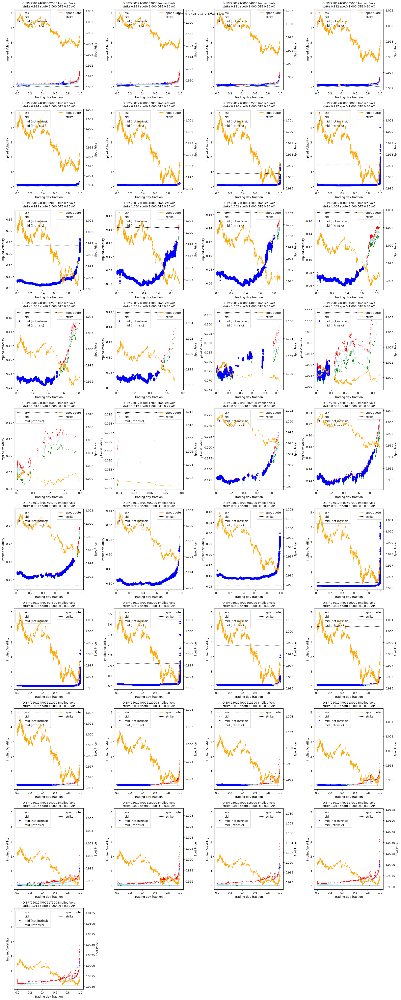

## Expiry 2025-01-27 for SPY 2025-01-24

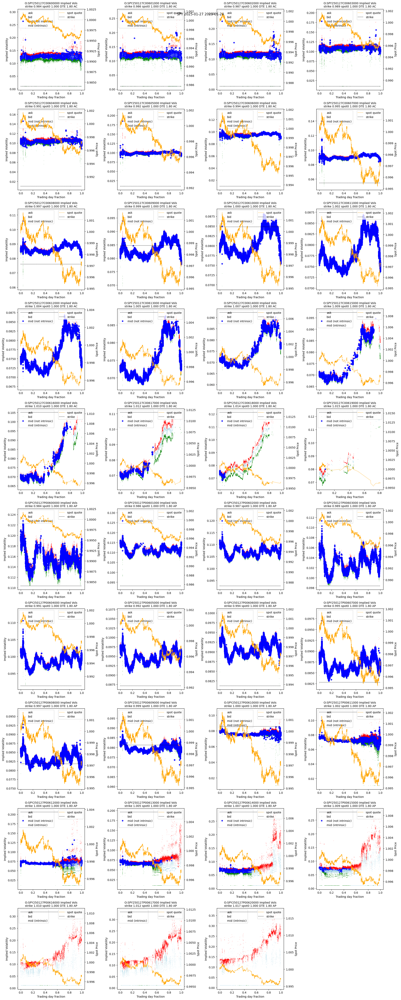

## Expiry 2025-01-28 for SPY 2025-01-24

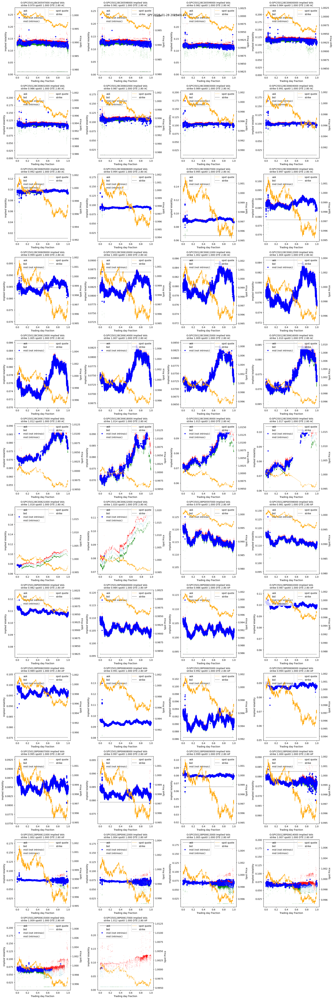

## Expiry 2025-01-29 for SPY 2025-01-24

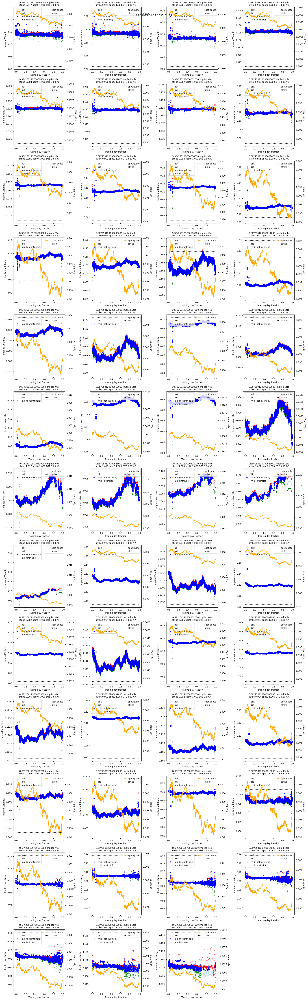

## Expiry 2025-01-30 for SPY 2025-01-24

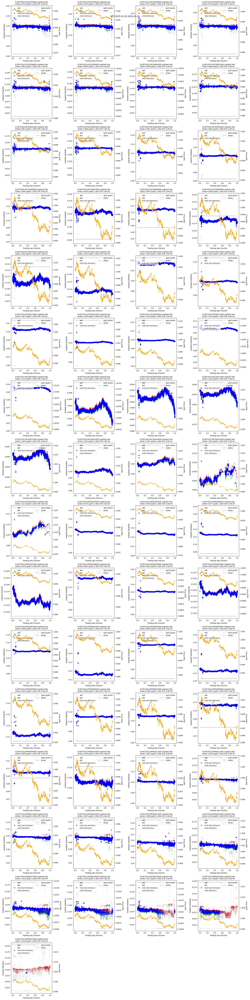

## Expiry 2025-01-31 for SPY 2025-01-24

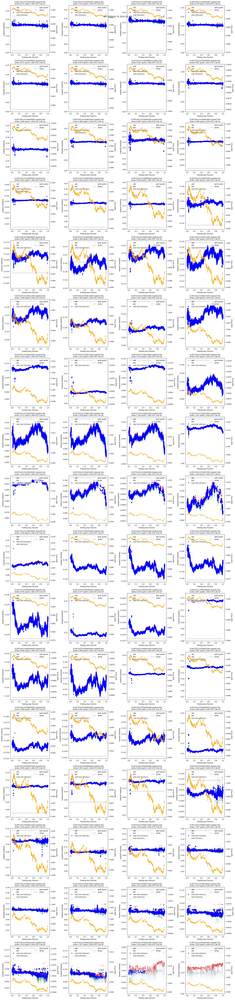

## Expiry 2025-02-03 for SPY 2025-01-24

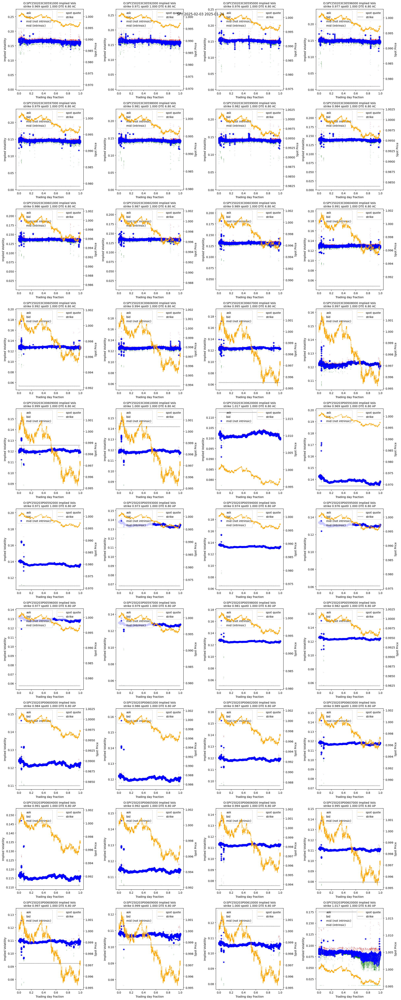

## Expiry 2025-02-04 for SPY 2025-01-24

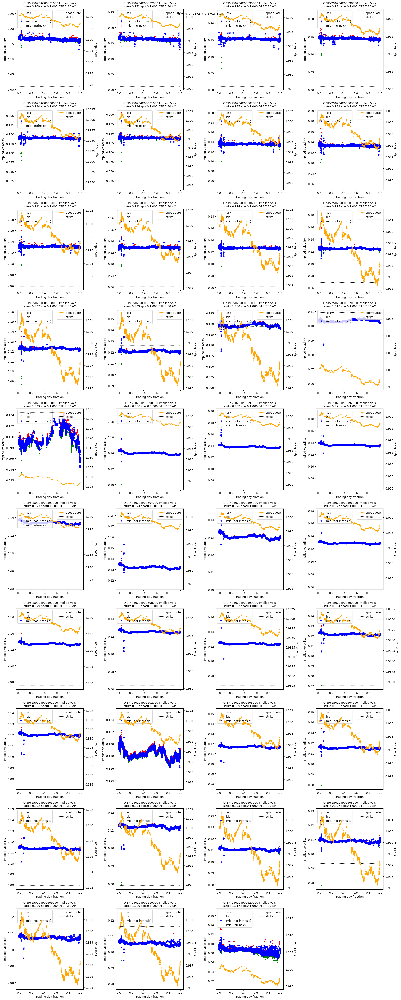

In [3]:
from cdxcore.dynaplot import figure, colors_tableau

def plot_expiry( ticker, d, expiry ):
    display(Markdown(f"## Expiry {expiry} for {ticker} {d}"))

    opt_tickers = sorted( df_dict["opt_ticker"].unique().to_list() )
    date = df_dict["date"].unique()[0] if "date" in df_dict.columns else d

    with figure(f"SPY {expiry} {date}", row_size=5, col_size=5, columns=4) as fig:

        for opt_ticker in opt_tickers:
            df_opt = df_dict.filter(pl.col("opt_ticker") == opt_ticker)
            slc    = slice(None,None)

            opt_mid_vol      = df_opt["mid_vol"].to_numpy()[slc]
            opt_ask_vol      = df_opt["ask_vol"].to_numpy()[slc]
            opt_bid_vol      = df_opt["bid_vol"].to_numpy()[slc]
            spot_mid_price   = df_opt["spot_mid_price"].to_numpy()[slc]
            spot_quote_t_d   = df_opt["spot_quote_t_d"].to_numpy()[slc]
            t_d              = df_opt["t_d"].to_numpy()[slc]
            is_intrinsic     = df_opt["is_intrinsic"].to_numpy()[slc]

            strike           = df_opt["strike"].unique()[0]
            is_call          = df_opt["is_call"].unique()[0]
            is_american      = df_opt["is_american"].unique()[0]
            dte_0            = df_opt["dte"].to_numpy()[0]

            ax = fig.add_subplot()
            ax.set_title(f"{opt_ticker} Implied Vols\nstrike {strike:.3f} spot0 {spot_mid_price[0]:.3f} DTE {dte_0:.2f} {'A' if is_american else 'E'}{'C' if is_call else 'P'}", fontsize=10)
            ax2 = ax.twinx()
            ax.plot(t_d, opt_ask_vol, ",", color="red", label="ask")
            ax.plot(t_d, opt_bid_vol, ",", color="green", label="bid")
            if not np.all(is_intrinsic):
                ax.plot(t_d[~is_intrinsic], opt_mid_vol[~is_intrinsic], "*", color="blue", label="mid (not intrinsic)")
            if np.any(is_intrinsic):
                ax.plot(t_d[is_intrinsic], opt_mid_vol[is_intrinsic], ",", color="lightblue", label="mid (intrinsic)")

            ax2.plot(spot_quote_t_d, spot_mid_price, ":", color="orange", label="spot quote")
            ax2.plot(spot_quote_t_d, spot_quote_t_d*0.+strike, ":", color="black", label="strike")

            ax.set_xlabel("Trading day fraction")
            ax.set_ylabel("Implied Volatility")
            ax2.set_ylabel("Spot Price")
            ax.legend(loc="upper left")
            ax2.legend(loc="upper right")

for expiry, df_dict in results.items():
    plot_expiry( ticker, d, expiry )





In [4]:
zdte = results[date(2025, 1, 23)].filter(pl.col("opt_ticker") == "O:SPY250123P00603000")
zdte = zdte.with_columns( ( pl.col("mid_price") - pl.col("half_spread") ).alias("bid_price") )

pl.Config.set_tbl_rows(-1)
display(zdte['strike', 'dte', 'bid_price', "intrinsic", "is_intrinsic", "bid_vol", "opt_tick_size"].tail(100))

KeyError: datetime.date(2025, 1, 23)

In [ ]:
from cdxcore.bs import bs

bs.price( 1.004221, )